# Example 8: random rectangle

A random axis-aligned rectangle between the origin and the opposite vertex $(\cos\gamma, \sin\gamma)^\top$, where $\gamma$ is uniform in the interval $(0,\pi/2)$. The notebook computes its quantile sets $K_\alpha$ from a sample, compares them with the coverage-based quantiles $Q_\alpha$, and shows the other plots discussed in the Section 5 of the paper.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

from Polytope import Polytope
from PolytopeRandomSet import PolytopeRandomSet
from utils import set_plotting_style, save_figure

set_plotting_style()

SAVE_FIGURES = False   # set to True to export the figures used in the paper (folder /images must exist)

### 1. Sample
The sample consists of 10,000 random rectangles (fixed seed for reproducibility).

In [2]:
rng = np.random.default_rng(2026)

def random_rectangle():
    """Rectangle [0, cos(t)] x [0, sin(t)] with t ~ Uniform(0, pi/2)."""
    a = rng.uniform(0, np.pi/2)
    return Polytope(V=[(0, 0), (np.cos(a), 0), (np.cos(a), np.sin(a)), (0, np.sin(a))])

RS = PolytopeRandomSet([random_rectangle() for _ in range(10_000)])
alphas = np.linspace(0, 1, 31)

### 2. Quantile sets $K_\alpha$
Sample quantiles for 31 equally spaced levels $\alpha \in [0, 1]$, colored by $\alpha$.

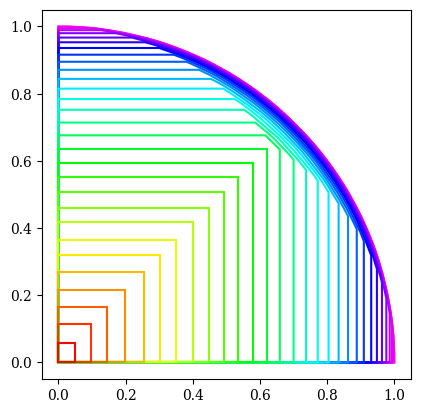

In [3]:
RS.plot_quantiles(alphas)
if SAVE_FIGURES:
    plt.setp(plt.gca(), xticks=(0, 0.5, 1), yticks=(0, 0.5, 1))
    save_figure(plt.gcf(), "images/rand_rectangle_quantiles_1", fig_size=(4, 4))
plt.show()

Individual quantiles for $\alpha = 0.4, 0.5, 0.6$. Note that the shape changes from a cropped square to a rectangle (at $\alpha\approx 0.56$).

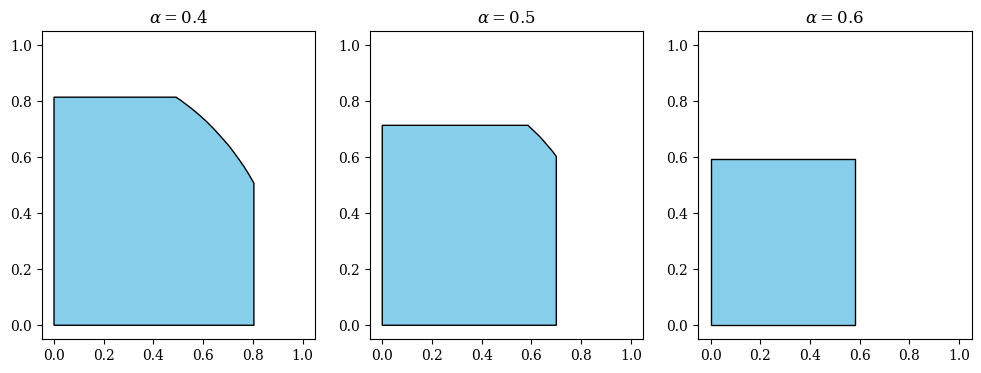

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a_ax, alpha in zip(ax, (0.4, 0.5, 0.6)):
    RS.quantile(alpha).plot(ax=a_ax)
    a_ax.set_title(f"$\\alpha={alpha}$")
plt.setp(ax, xlim=(-0.05, 1.05), ylim=(-0.05, 1.05))
plt.show()

### 3. Comparison with coverage-based quantiles
The coverage-based quantile is the level set $\{x : \mathsf P(x \in X) \ge \alpha\}$ of the coverage function. For this example it is bounded by the axes $x = 0$, $y = 0$
and the curve $y = \sin\!\left(\arccos x - \tfrac{\alpha\pi}{2}\right)$, which follows from evaluating the coverage probability analytically. The sets plotted below are therefore *theoretical*, not computed from the sample.

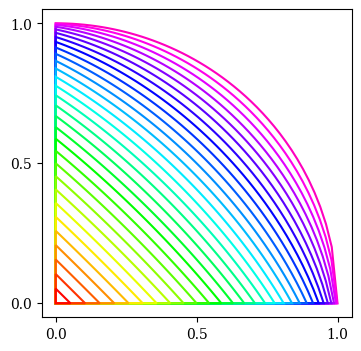

In [5]:
fig, ax = plt.subplots(figsize=(4, 4))
for alpha in alphas:
    pts = [(0, 0)] + [(x, np.sin(np.arccos(x) - alpha*np.pi/2))
                      for x in np.linspace(0, np.cos(alpha*np.pi/2))]
    ax.add_patch(Polygon(pts, fill=False, ec=plt.get_cmap("gist_rainbow_r")(alpha), lw=1.5))
ax.margins(0.05)
plt.setp(ax, xticks=(0, 0.5, 1), yticks=(0, 0.5, 1))
if SAVE_FIGURES: save_figure(fig, "images/rand_rectangle_quantiles_2", fig_size=(4, 4))
plt.show()

### 4. Pairplot, symmetry plot and containment-capacity plot

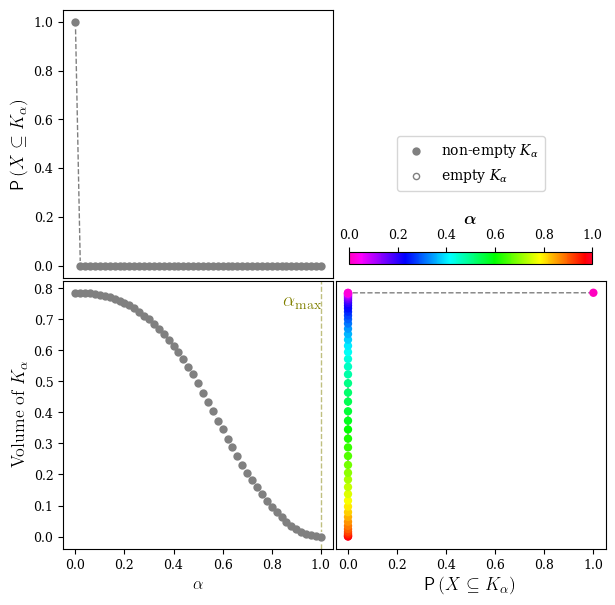

In [6]:
RS.pairplot()
plt.show()

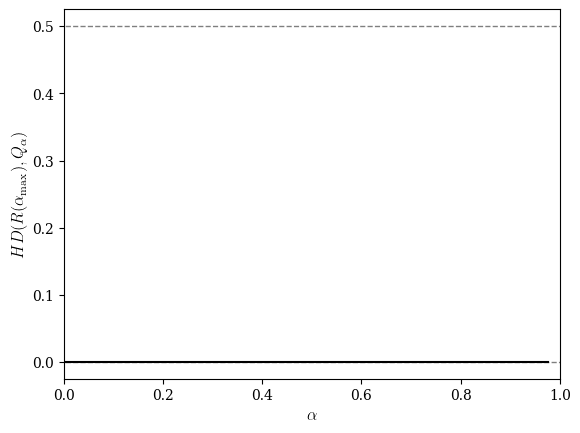

In [7]:
RS.symmetry_plot(seed=2026)
if SAVE_FIGURES: save_figure(plt.gcf(), "images/rand_rectangle_symmetry_plot", fig_size=(4, 4))
plt.show()

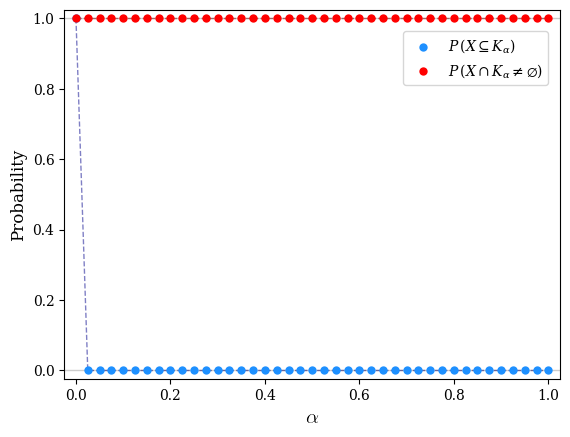

In [8]:
RS.containment_capacity_plot()
plt.show()